# μP hyperparameter sweep results

We tuned the peak **base learning rate (LR)** and hidden matrix **weight decay** on a width-128 proxy, then tested leading settings at the intended width of 256. The base width was 64 throughout. μP uses the base LR for embeddings and the readout and multiplies it by 64 / model width for hidden matrices.

Each point below is the **best validation loss recorded for one candidate**. Lower is better. The JSONL files store candidate summaries. The console showed intermediate losses, so the plots compare candidates rather than reconstructing training curves.

The first two figures show how we explored the search space before fixing an extra width factor in μP attention. The last figure shows the reruns with corrected attention. Open the saved plots below or run the cells with the project’s analysis environment. This notebook reads saved results and requires no GPU.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
results = root / "artifacts" / "pretraining"

def load(name):
    path = results / f"mup-{name}.jsonl"
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]

def plot_candidates(ax, rows, x_key, color="#2563a8"):
    rows = sorted(rows, key=lambda row: row[x_key])
    xs = [row[x_key] for row in rows]
    ys = [row["best_validation_loss"] for row in rows]
    ax.plot(xs, ys, color=color, marker="o", linewidth=1.7)
    best = min(rows, key=lambda row: row["best_validation_loss"])
    ax.scatter(best[x_key], best["best_validation_loss"], marker="*", s=160,
               color="#a23c12", zorder=3)
    ax.set_ylabel("Best validation loss")
    ax.grid(axis="y", alpha=0.25)
    return best

def lr_axis(ax, ticks):
    ax.set_xscale("log")
    ax.set_xticks(sorted(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(axis="x", labelrotation=55)
    ax.set_xlabel("Peak base LR")

## Initial search with the earlier attention scale

- **First pass.** At width 128, we tried three LRs for 1,000 updates each with batch 10 and weight decay 0.05. Validation loss improved at every increase, so we expanded the range.
- **LR bracket.** We switched to effective batch 80 (eight microbatches of 10, matching the 2B run), 2,000 updates, and 100 warmup steps. At decay 0.05, the wider search and refinement favored base LR 0.0136.
- **Decay bracket.** We fixed LR at 0.0136 and varied decay. The best tested decay was 0.6. Neither the tighter LR search nor the decay bracket was a full grid over both parameters.

Every candidate within a stage started fresh with seed 42, used the same sampled batches, and decayed LR to one tenth of its peak. The first pass used 2.56M training targets per candidate. Each later candidate used 40.96M.

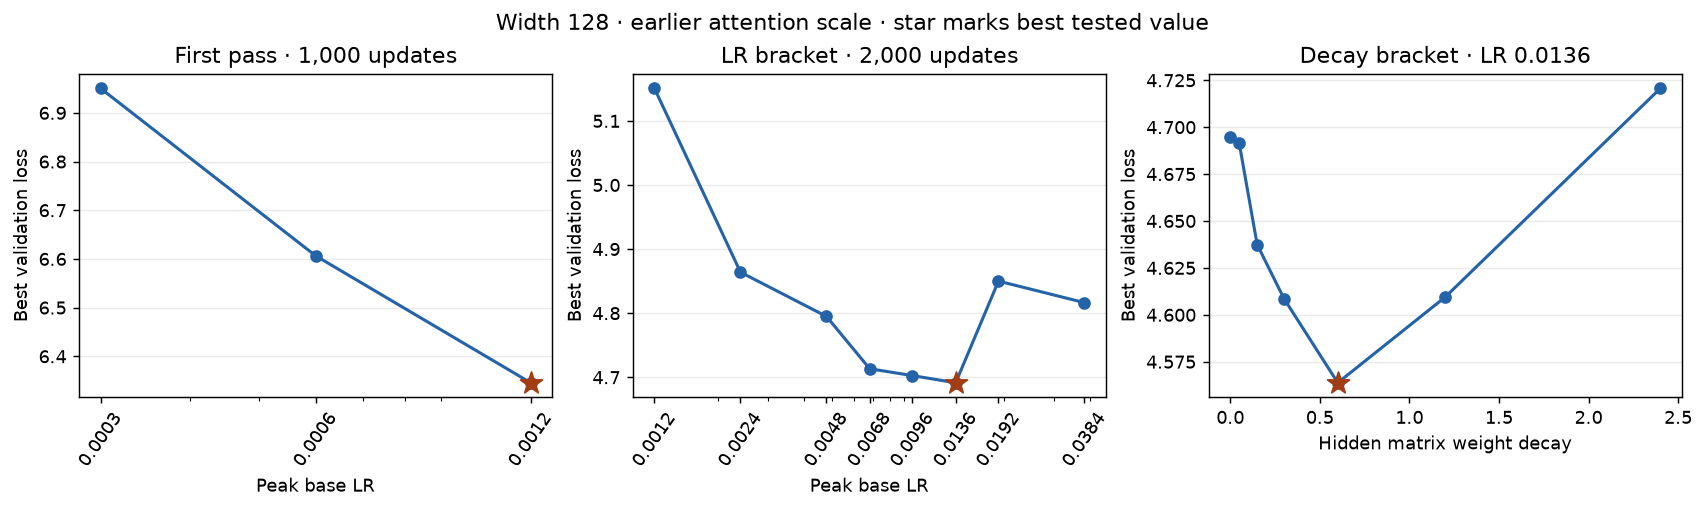

In [2]:
first = load("proxy-sweep")
lr_grid = load("proxy-serious-lr") + load("proxy-serious-refine")
decay_grid = load("proxy-serious-decay") + [
    row for row in lr_grid if row["proxy_peak_lr"] == 0.0136
]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, rows, title in zip(axes[:2], [first, lr_grid],
                           ["First pass · 1,000 updates", "LR bracket · 2,000 updates"]):
    plot_candidates(ax, rows, "proxy_peak_lr")
    lr_axis(ax, [row["proxy_peak_lr"] for row in rows])
    ax.set_title(title)
plot_candidates(axes[2], decay_grid, "weight_decay")
axes[2].set(title="Decay bracket · LR 0.0136", xlabel="Hidden matrix weight decay")
fig.suptitle("Width 128 · earlier attention scale · star marks best tested value")
plt.show()

## Width 256 with the earlier attention scale

We tested four LRs at decay 0.6 and compared decay 0.6 with 1.2 at LR 0.0192. The best pair was 0.0192 and 0.6 (4.392). Decay 1.2 was close at 4.398. This stage motivated rerunning the two leading LRs after correcting the attention scale.

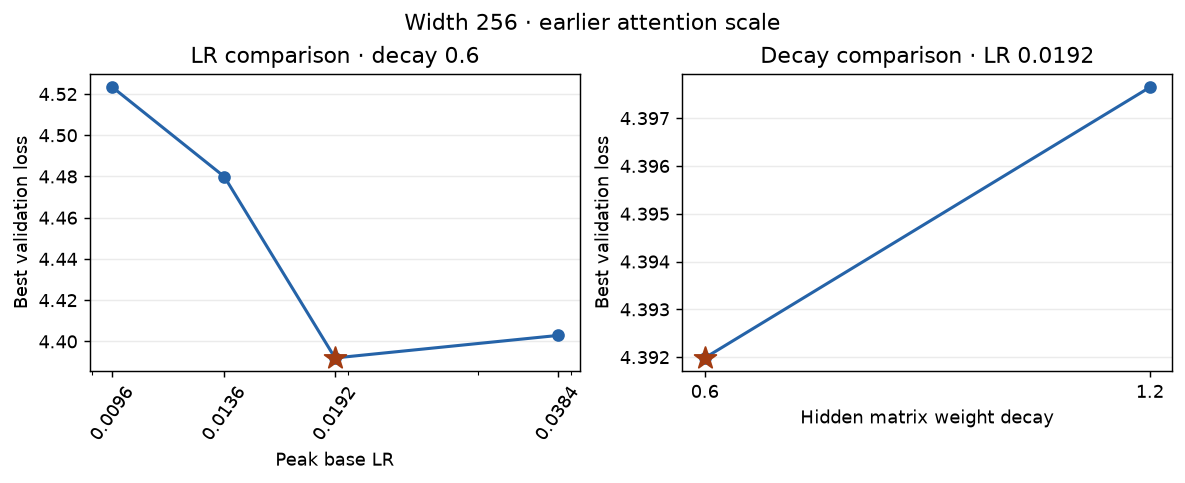

In [3]:
target = load("target-serious")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
lr_rows = [row for row in target if row["weight_decay"] == 0.6]
plot_candidates(axes[0], lr_rows, "proxy_peak_lr")
lr_axis(axes[0], [row["proxy_peak_lr"] for row in lr_rows])
axes[0].set_title("LR comparison · decay 0.6")
plot_candidates(axes[1], [row for row in target if row["proxy_peak_lr"] == 0.0192],
                "weight_decay")
axes[1].set(title="Decay comparison · LR 0.0192", xlabel="Hidden matrix weight decay")
axes[1].set_xticks([0.6, 1.2])
fig.suptitle("Width 256 · earlier attention scale")
plt.show()

## Reruns with corrected attention

We removed an extra base-width / model-width factor from the attention score scaling, leaving 1 / head dimension. Then we reran the **same two base LRs at both widths**, with decay 0.6 and 2,000 updates per candidate. These four runs are the direct transfer comparison.

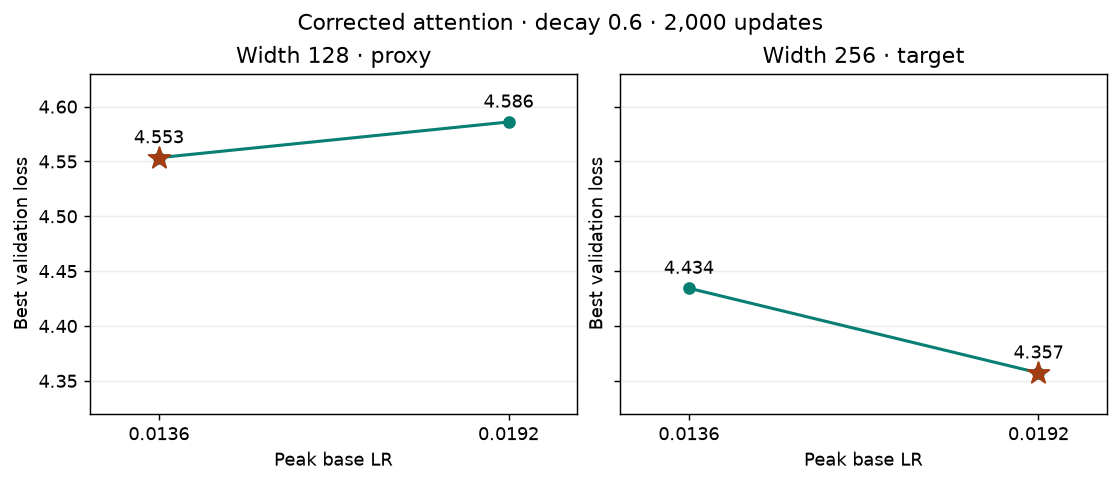

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6), sharey=True, layout="constrained")
for ax, role, width in zip(axes, ("proxy", "target"), (128, 256)):
    rows = load(f"{role}-attention-corrected")
    plot_candidates(ax, rows, "proxy_peak_lr", color="#087f73")
    ax.set(title=f"Width {width} · {role}", xlabel="Peak base LR",
           xlim=(0.0125, 0.0203), xticks=[0.0136, 0.0192])
    for row in rows:
        loss = row["best_validation_loss"]
        ax.annotate(f"{loss:.3f}", (row["proxy_peak_lr"], loss),
                    xytext=(0, 8), textcoords="offset points", ha="center")
axes[0].set_ylim(4.32, 4.63)
fig.suptitle("Corrected attention · decay 0.6 · 2,000 updates")
plt.show()

| Peak base LR | Width 128 | Width 256 |
| ---: | ---: | ---: |
| 0.0136 | **4.553** | 4.434 |
| 0.0192 | 4.586 | **4.357** |

The two rates traded places. The proxy favored 0.0136 by 0.033 loss, and the target favored 0.0192 by 0.077. At width 256, base LR 0.0192 gives a peak hidden matrix LR of 0.0048.

**For a 2B run**, 0.0192 with decay 0.6 is the strongest tested starting point at width 256 with corrected attention. The corrected runs all used decay 0.6, one seed, and about 41M training targets with cosine decay ending at step 2,000. The best decay and LR for a 100,000-update schedule remain open.

## Matched four-width test

All 44 candidates completed with seed 42 and weight decay zero. The left panel shows final validation loss across learning rates. Stars mark each width’s best tested rate. The right panel shows how validation loss changed during training at the rate selected by width 32. The throughput figure uses candidate averages that exclude validation.


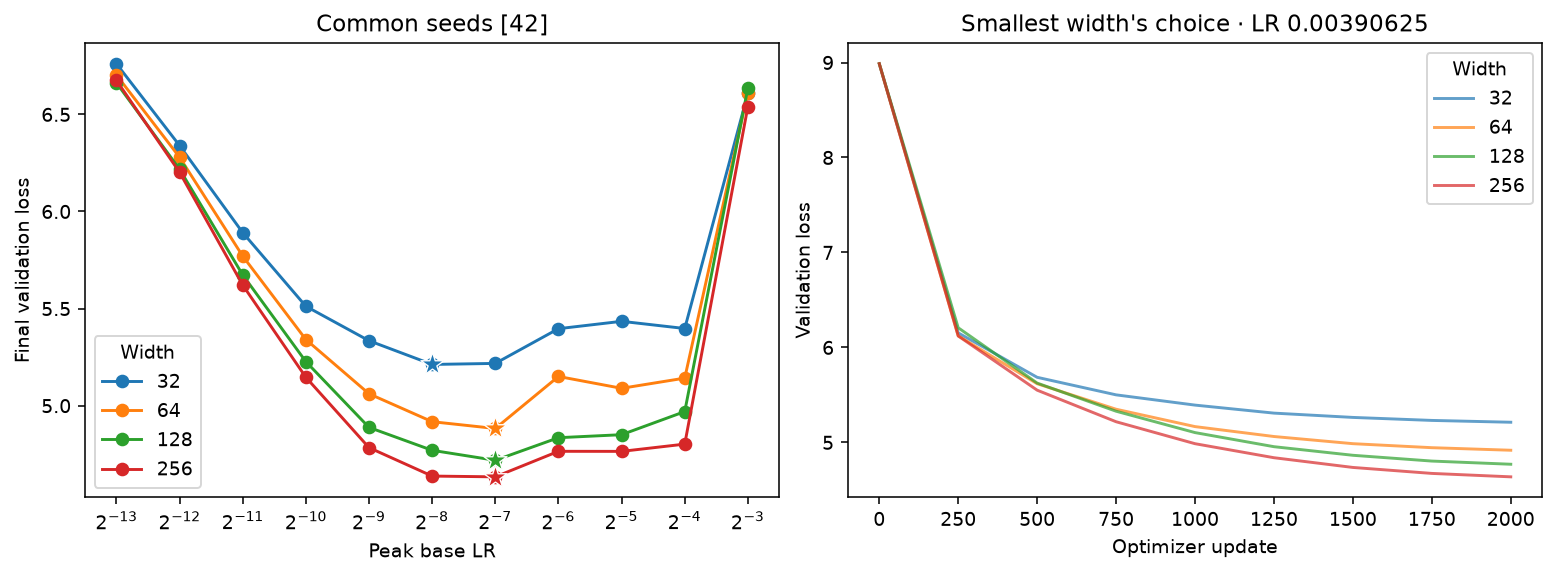

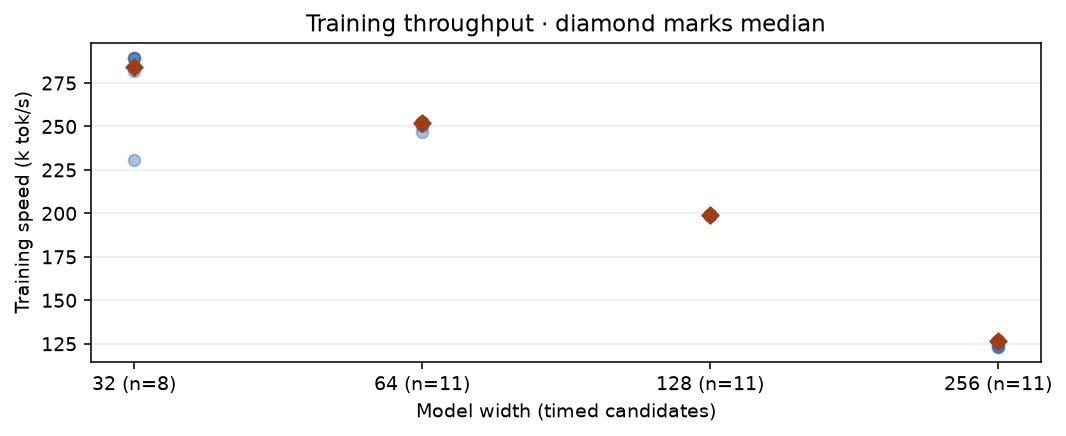

In [5]:
from collections import defaultdict
from statistics import mean, median, stdev
from math import isclose, log2

grid_name = "width-grid-powers-of-two"
grid_path = results / f"mup-{grid_name}.jsonl"
if not grid_path.is_file():
    print("Run the four-width sweep to populate this plot.")
else:
    groups = defaultdict(dict)
    for row in load(grid_name):
        groups[row["proxy_width"], row["proxy_peak_lr"]][row["seed"]] = row
    widths = sorted({width for width, _ in groups})
    rates = sorted(set.intersection(*[{lr for w, lr in groups if w == width}
                                      for width in widths]))
    seeds = sorted(set.intersection(*(set(groups[width, lr])
                                      for width in widths for lr in rates))) if rates else []
    if not seeds:
        print("Waiting for a common grid of completed candidates.")
    else:
        fig, (ax, history) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
        def losses(width, lr):
            return [groups[width, lr][seed]["final_validation_loss"] for seed in seeds]

        proxy_lr = min(rates, key=lambda lr: mean(losses(widths[0], lr)))
        for width in widths:
            means = [mean(losses(width, lr)) for lr in rates]
            spread = [stdev(losses(width, lr)) for lr in rates] if len(seeds) > 1 else None
            line = ax.errorbar(rates, means, yerr=spread, marker="o", capsize=3,
                               label=str(width))
            best = min(range(len(rates)), key=means.__getitem__)
            ax.scatter(rates[best], means[best], color=line[0].get_color(),
                       marker="*", s=155, edgecolors="white", linewidths=0.7, zorder=5)
            for index, seed in enumerate(seeds):
                points = groups[width, proxy_lr][seed]["evaluations"]
                history.plot([p["step"] for p in points], [p["validation_loss"] for p in points],
                             color=line[0].get_color(), alpha=0.7,
                             label=str(width) if index == 0 else None)
        lr_axis(ax, rates)
        ax.set_xscale("log", base=2)
        ax.set_xticks(rates)
        ax.xaxis.set_major_formatter(FuncFormatter(
            lambda lr, _: rf"$2^{{{round(log2(lr))}}}$"
            if isclose(log2(lr), round(log2(lr))) else f"{lr:g}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.tick_params(axis="x", labelrotation=0)
        ax.set(ylabel="Final validation loss", title=f"Common seeds {seeds}")
        history.set(xlabel="Optimizer update", ylabel="Validation loss",
                    title=f"Smallest width's choice · LR {proxy_lr:g}")
        for panel in (ax, history):
            panel.legend(title="Width")
        plt.show()
        speeds = {width: [row["train_tokens_per_second"] / 1000
                          for lr in rates for row in groups[width, lr].values()
                          if "train_tokens_per_second" in row]
                  for width in widths}
        if any(speeds.values()):
            fig, speed_ax = plt.subplots(figsize=(7.5, 3), layout="constrained")
            for width, values in speeds.items():
                if values:
                    speed_ax.scatter([width] * len(values), values, alpha=0.38, color="#2563a8")
                    speed_ax.scatter(width, median(values), marker="D", color="#a23c12", zorder=3)
            speed_ax.set_xscale("log", base=2)
            speed_ax.set_xticks(widths, [f"{w} (n={len(speeds[w])})" for w in widths])
            speed_ax.set(xlabel="Model width (timed candidates)", ylabel="Training speed (k tok/s)",
                         title="Training throughput · diamond marks median")
            speed_ax.grid(axis="y", alpha=0.25)
            plt.show()


| Width | Best tested LR | Final validation loss | Median training tok/s |
| ---: | ---: | ---: | ---: |
| 32 | 2⁻⁸ | 5.2123 | 284k |
| 64 | 2⁻⁷ | 4.8824 | 252k |
| 128 | 2⁻⁷ | 4.7186 | 199k |
| 256 | 2⁻⁷ | 4.6335 | 127k |

At width 256, using width 32’s preferred LR (2⁻⁸) gives 4.6374, just 0.0039 above the best tested loss. The sweep points to a shared useful LR region around 2⁻⁸ to 2⁻⁷ for this seed, 2,000-update schedule, and zero decay. Repeat near that region across seeds to see how stable the differences are.

Throughput is available for 41 of 44 candidates. Width 256 runs at about 45% of width 32’s median training throughput under this sweep setup.